   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.7/225.7 kB 1.5 MB/s eta 0:00:00
=== FIN_LOG v1.0 | MODE = ROBUST ===
  Estimations : 5 | Fenêtre : 120j | Test : cliff_delta
  Seuil critique (hypothèse) : 65.0e percentile

Gradient de Stress : 26 points
[Yahoo Finance] Téléchargement BTC-USD (5y, 1d)...
[OK] 1827 bougies | 2021-07-16 → 2026-07-16

[1/5] Scan du seuil critique (50–80e percentile)...


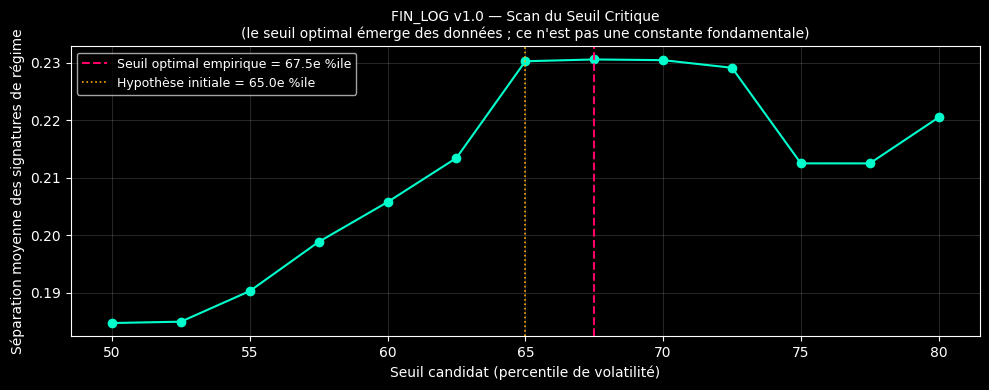


[Scan du seuil critique]
  Hypothèse initiale  : 65.0e percentile
  Seuil optimal (données actuelles) : 67.5e percentile  (séparation = 0.231)
  Note : ce seuil dépend de la fenêtre d'analyse et du marché actuel.
         Il est robuste si la courbe ci-dessus présente un plateau stable.

[2/5] Vue d'ensemble prix + stress...


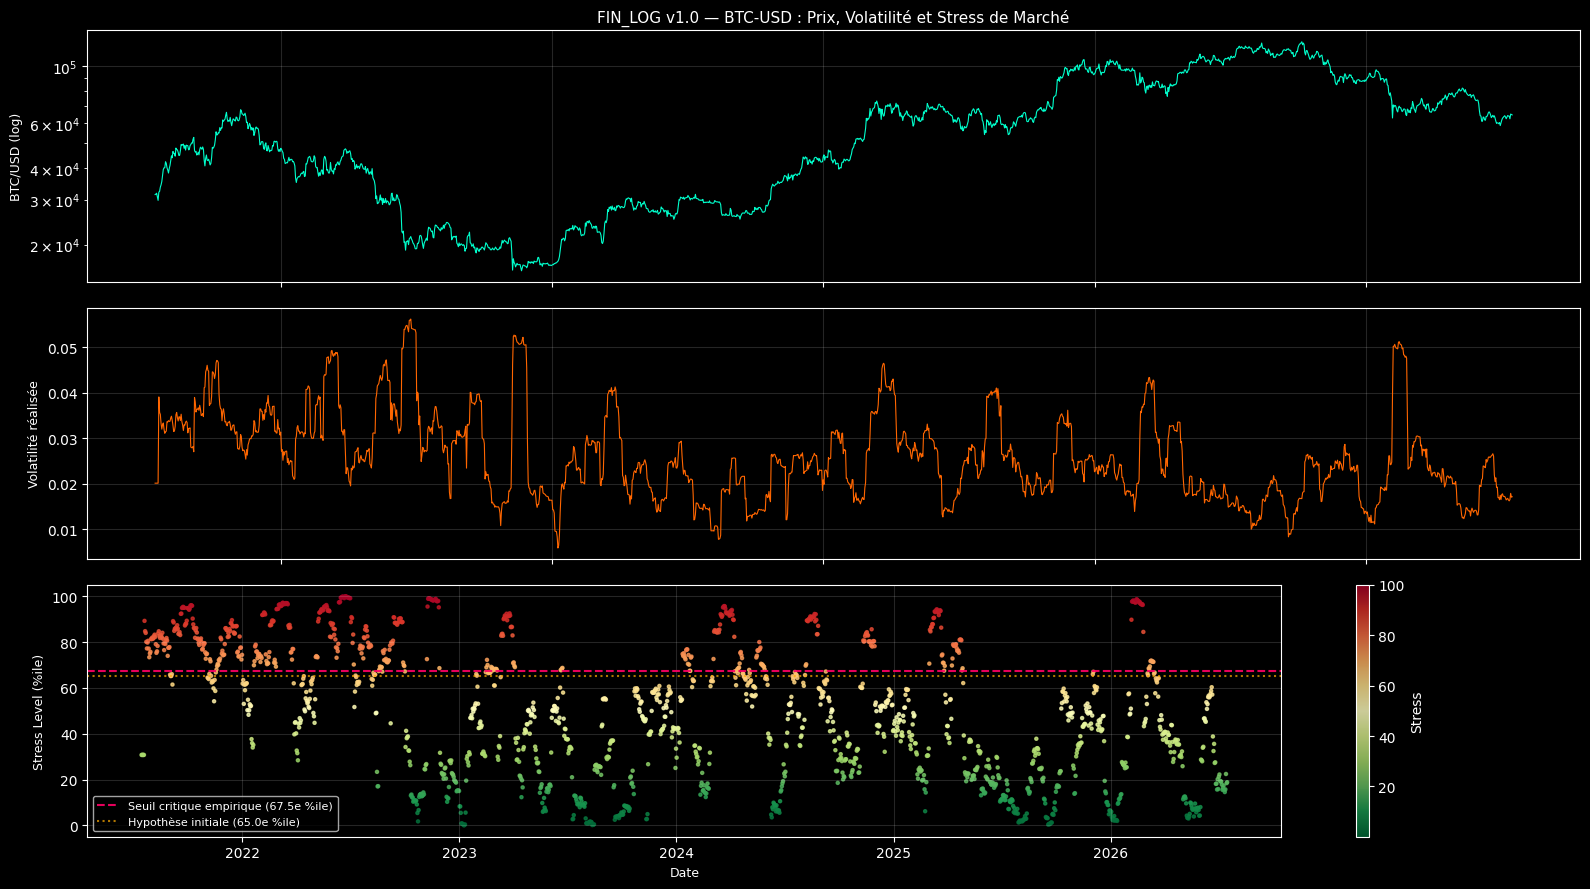


[3/5] Profils des 5 flux financiers...


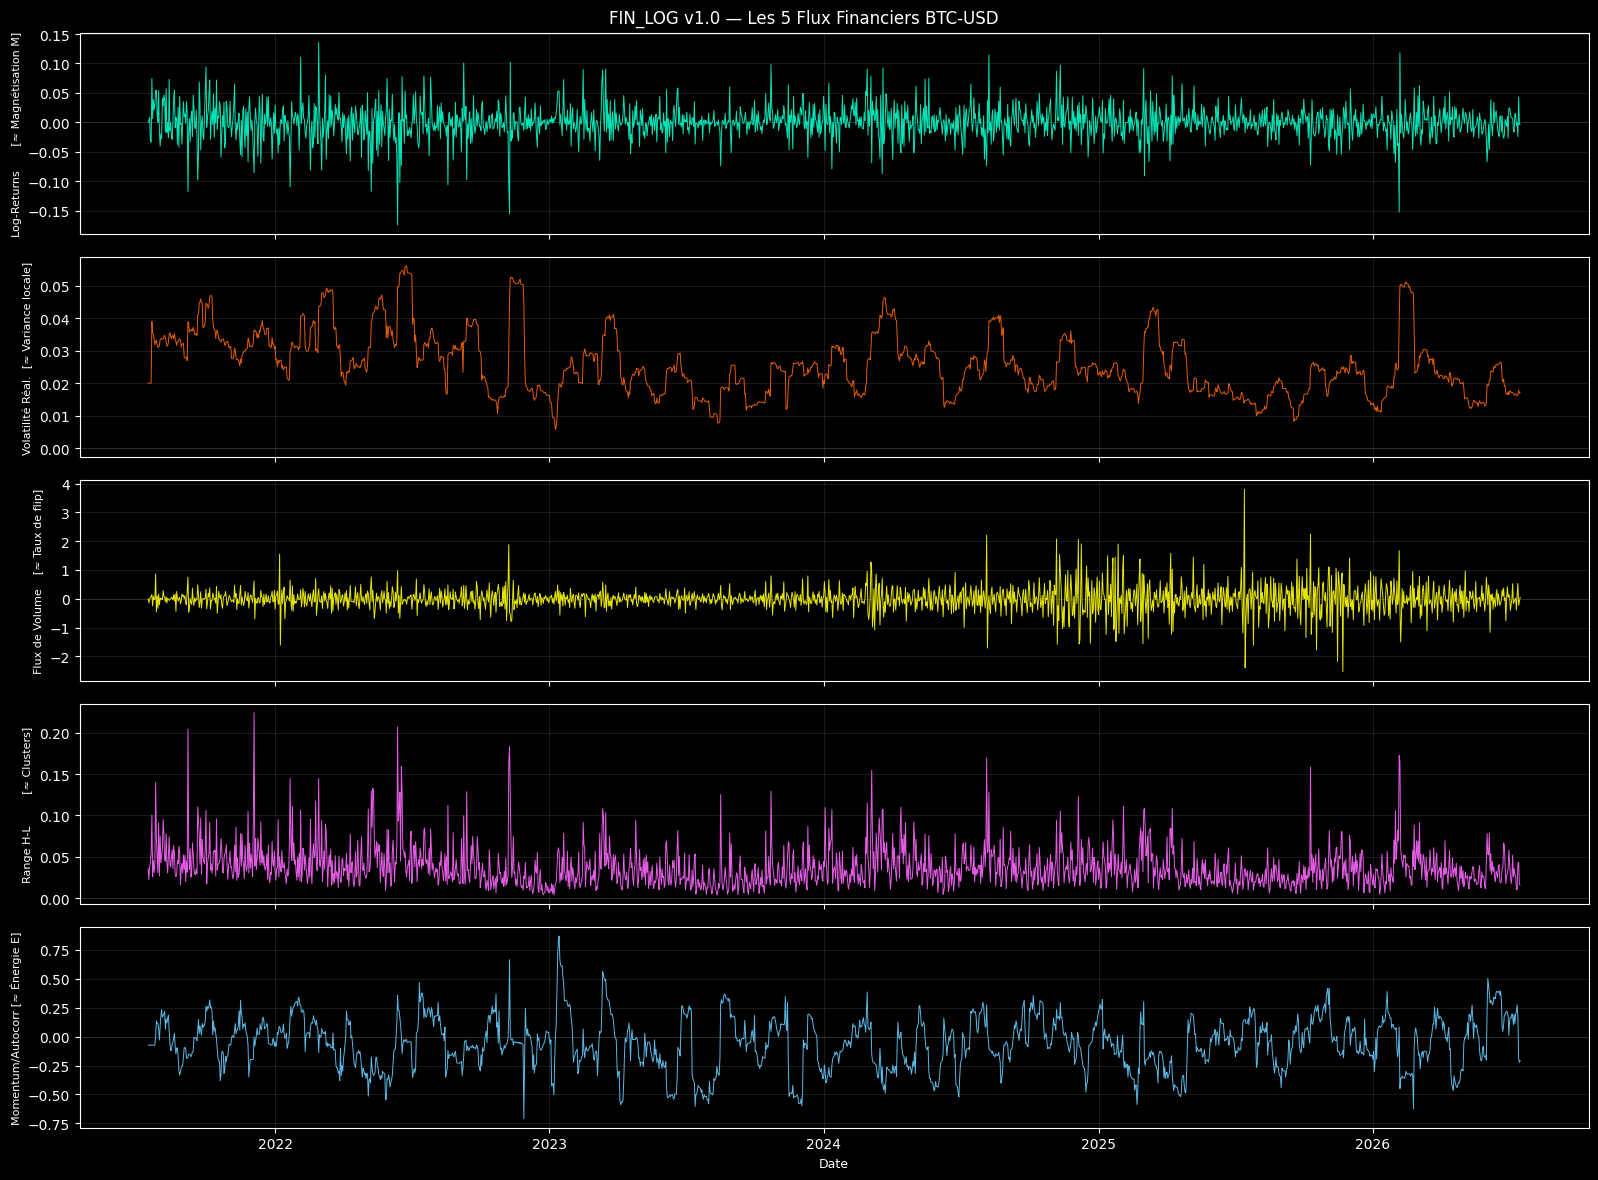


[4/5] Extraction des signatures de régime...

[Extraction des signatures de régime] 5 bootstrap sur sous-fenêtres (estimation de stabilité statistique) | Fenêtre=120j


Scan de stress: 100%|██████████| 26/26 [10:17<00:00, 23.74s/it]


  Signatures extraites : 25
   Stress  N_windows  Log_Returns_Higuchi_mean  Log_Returns_DFA_mean  Log_Returns_Katz_mean  Log_Returns_Hurst_mean
0     5.0          1                  2.062769              1.670005               4.205981                0.199676
1    10.0          1                  2.062769              1.715774               4.205981                0.192370
2    15.0         62                  2.060267              1.984742               8.166144                0.125073


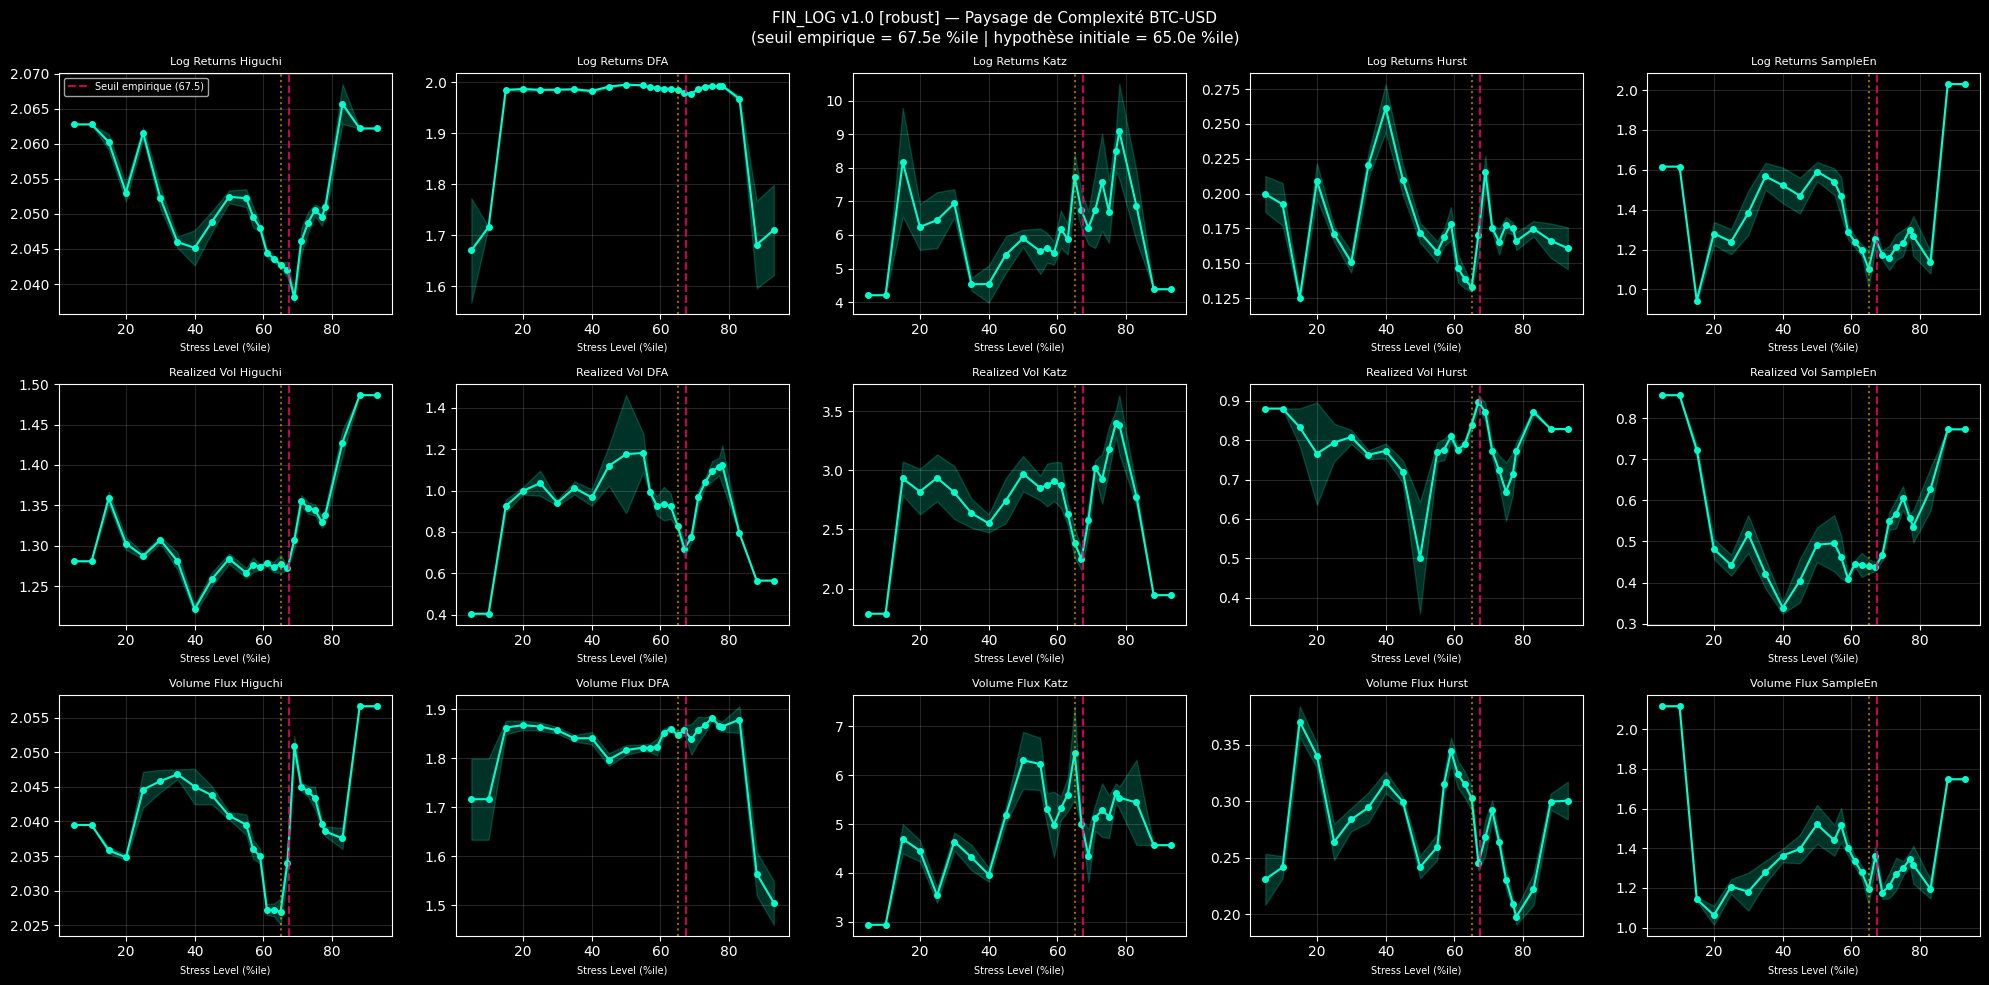


[5/5] 4 Questions financières...

=== 4 Questions Financières (seuil critique empirique = 67.5e %ile) ===
Q1 : Bull vs Bear (Marché calme vs Chaotique)...
Q2 : Tension au Seuil Critique (Zone de transition de régime)...
Q3 : Apathie vs Dynamisme (flux d'activité)...
Q4 : Persistance de Régime (Hystérésis intra-fenêtre)...

>>> RÉSULTATS — Scores de séparation des signatures de régime :
                            Q1_Bull_vs_Bear  Q2_Tension_Critique  Q3_Apathie_vs_Dynamisme  Q4_Persistance_Regime
Log_Returns_DFA_mean                  0.190                0.467                      NaN                  0.082
Log_Returns_Higuchi_mean              0.048                0.467                      NaN                  0.082
Log_Returns_Hurst_mean                0.286                0.533                      NaN                  0.082
Log_Returns_Katz_mean                 0.333                0.800                      NaN                  0.082
Log_Returns_SampleEn_mean             0.000  

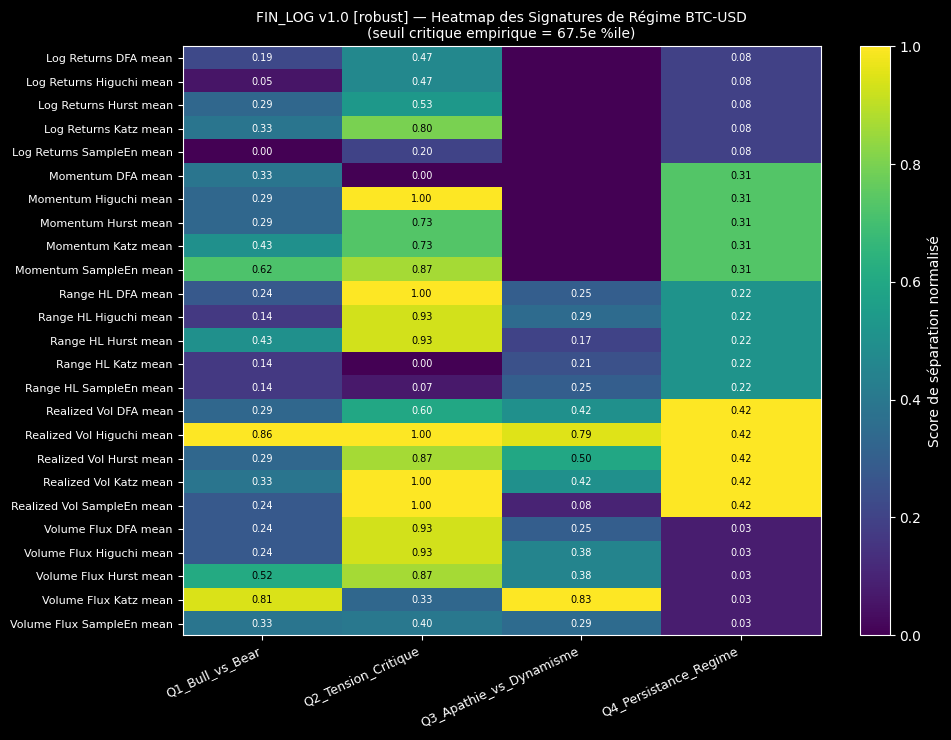


[OK] FIN_LOG v1.0 terminé. Seuil critique utilisé : 67.5e percentile


In [1]:
!pip install -q nolds antropy yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')
import antropy, nolds

plt.style.use('dark_background')

# =============================================================================
# FIN_LOG v1.0 — Analyse de Complexité pour Séries Temporelles Financières
# =============================================================================
# Paramètre de contrôle : percentile de volatilité réalisée (0–100)
#
# SEUIL CRITIQUE (STRESS_CRITIQUE) :
#   Contrairement à Tc dans le modèle d'Ising (valeur analytique exacte),
#   il n'existe pas de point critique exact en finance. Le seuil ci-dessous
#   est une HYPOTHÈSE DE TRAVAIL (65e percentile = zone de transition de
#   régime observée empiriquement sur BTC). La fonction scan_seuil_critique()
#   teste la plage 50–80 % et identifie le seuil qui maximise la séparation
#   des signatures de régime dans les données actuelles.
#
# MODE ROBUST — "n_estimations" :
#   En physique, plusieurs réalisations du système ont un sens fondamental.
#   En finance, le marché n'a eu lieu qu'une seule fois : le bootstrap
#   sur sous-fenêtres est une ESTIMATION DE STABILITÉ STATISTIQUE, pas
#   une simulation de marchés alternatifs.
# =============================================================================

STRESS_CRITIQUE_HYPOTHESE = 65.0   # hypothèse de travail initiale
MODE = 'robust'                       # 'fast' ou 'robust'

CONFIG = {
    'fast': {
        'n_estimations': 1,
        'window_size': 60,
        'stat_test': 'cohen_d',
        'min_per_group': 2,
        'estimator_min_len': 50,
        'mann_whitney': False,
        'bootstrap': False,
    },
    'robust': {
        'n_estimations': 5,       # estimations de stabilité statistique (bootstrap)
        'window_size': 120,
        'stat_test': 'cliff_delta',
        'min_per_group': 3,
        'estimator_min_len': 100,
        'mann_whitney': True,
        'bootstrap': True,
    }
}
C = CONFIG[MODE]
print(f"=== FIN_LOG v1.0 | MODE = {MODE.upper()} ===")
print(f"  Estimations : {C['n_estimations']} | Fenêtre : {C['window_size']}j | Test : {C['stat_test']}")
print(f"  Seuil critique (hypothèse) : {STRESS_CRITIQUE_HYPOTHESE}e percentile")

# =============================================================================
# 0. STATISTIQUES
# =============================================================================

def cohen_d(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    if len(g1) < 2 or len(g2) < 2:
        return np.nan
    pooled_std = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    return 0.0 if pooled_std < 1e-12 else (np.mean(g1) - np.mean(g2)) / pooled_std

def cliff_delta(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']:
        return np.nan, np.nan
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return np.clip((2 * U - n1 * n2) / (n1 * n2), -1, 1), np.nan
    except:
        return np.nan, np.nan

def separation_score(g1, g2):
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d, _ = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan

def mw_score(g1, g2):
    if not C['mann_whitney']:
        return np.nan
    try:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return -np.log10(max(p, 1e-300))
    except:
        return np.nan

# =============================================================================
# 1. ACQUISITION — Yahoo Finance
# =============================================================================

def fetch_btcusdt(period='5y', interval='1d'):
    print(f"[Yahoo Finance] Téléchargement BTC-USD ({period}, {interval})...")
    raw = yf.download('BTC-USD', period=period, interval=interval, progress=False, auto_adjust=True)
    if raw.empty:
        raise ValueError("Aucune donnée reçue de Yahoo Finance.")
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = [col[0] for col in raw.columns]
    df = raw[['Open','High','Low','Close','Volume']].copy()
    df = df.dropna(subset=['Close']).reset_index()
    df = df.rename(columns={'index': 'Date', 'Datetime': 'Date', 'Price': 'Date'})
    if 'Date' not in df.columns:
        df = df.rename(columns={df.columns[0]: 'Date'})
    df['Date'] = pd.to_datetime(df['Date'])
    for col in ['Open','High','Low','Close','Volume']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df.sort_values('Date').reset_index(drop=True)
    print(f"[OK] {len(df)} bougies | {df['Date'].iloc[0].date()} → {df['Date'].iloc[-1].date()}")
    return df

def extract_financial_fluxes(df, vol_window=20):
    out = {}
    log_ret = np.log(df['Close'] / df['Close'].shift(1)).fillna(0).values
    out['Log_Returns'] = log_ret

    r_series = pd.Series(log_ret)
    rv = r_series.rolling(vol_window, min_periods=5).std()
    out['Realized_Vol'] = rv.bfill().ffill().fillna(0).values

    vol = df['Volume'].values.astype(float)
    vol_mean = np.mean(vol[vol > 0]) if np.any(vol > 0) else 1.0
    out['Volume_Flux'] = np.diff(vol, prepend=vol[0]) / (vol_mean + 1e-10)

    out['Range_HL'] = ((df['High'] - df['Low']) / df['Close'].replace(0, np.nan)).fillna(0).values

    momentum = r_series.rolling(vol_window, min_periods=10).apply(
        lambda x: float(pd.Series(x).autocorr(lag=1)) if len(x) > 5 else 0.0,
        raw=False
    ).bfill().ffill().fillna(0)
    out['Momentum'] = momentum.values

    return out

def compute_stress_level(fluxes):
    rv = fluxes['Realized_Vol']
    return np.array([stats.percentileofscore(rv, v) for v in rv])

# =============================================================================
# 2. SCAN DU SEUIL CRITIQUE — le seuil émerge des données
# =============================================================================

def scan_seuil_critique(df, candidats=None):
    """
    Teste une plage de seuils (50–80e percentile) et identifie celui qui
    maximise la séparation moyenne des signatures de régime entre les fenêtres
    sous le seuil et au-dessus. Le résultat est empirique : il dépend des
    données actuelles, pas d'une valeur théorique fixe.
    """
    if candidats is None:
        candidats = np.arange(50, 81, 2.5)

    fluxes    = extract_financial_fluxes(df)
    stress_s  = compute_stress_level(fluxes)
    W         = C['window_size']
    flux_keys = list(fluxes.keys())

    # Constitution des fenêtres glissantes (niveau de stress moyen + flux brut)
    windows = []
    for i in range(len(df) - W + 1):
        windows.append({
            'stress': float(np.mean(stress_s[i:i+W])),
            'data':   {k: fluxes[k][i:i+W] for k in flux_keys}
        })

    scores_par_seuil = []
    for seuil in candidats:
        grp_bas  = [w for w in windows if w['stress'] <  seuil]
        grp_haut = [w for w in windows if w['stress'] >= seuil]
        if len(grp_bas) < C['min_per_group'] or len(grp_haut) < C['min_per_group']:
            scores_par_seuil.append(np.nan)
            continue
        sep_total = []
        for k in flux_keys:
            v_bas  = np.concatenate([w['data'][k] for w in grp_bas])
            v_haut = np.concatenate([w['data'][k] for w in grp_haut])
            d = separation_score(v_bas, v_haut)
            if not np.isnan(d):
                sep_total.append(d)
        scores_par_seuil.append(np.mean(sep_total) if sep_total else np.nan)

    scores_arr = np.array(scores_par_seuil, dtype=float)
    idx_max    = np.nanargmax(scores_arr)
    seuil_opt  = candidats[idx_max]

    # Graphique : robustesse du seuil sur 50–80 %
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(candidats, scores_arr, 'o-', color='#00ffcc', markersize=6)
    ax.axvline(seuil_opt, color='#ff0066', linestyle='--', linewidth=1.5,
               label=f'Seuil optimal empirique = {seuil_opt:.1f}e %ile')
    ax.axvline(STRESS_CRITIQUE_HYPOTHESE, color='#ffaa00', linestyle=':', linewidth=1.2,
               label=f'Hypothèse initiale = {STRESS_CRITIQUE_HYPOTHESE}e %ile')
    ax.set_xlabel('Seuil candidat (percentile de volatilité)', fontsize=10)
    ax.set_ylabel('Séparation moyenne des signatures de régime', fontsize=10)
    ax.set_title('FIN_LOG v1.0 — Scan du Seuil Critique\n'
                 '(le seuil optimal émerge des données ; ce n\'est pas une constante fondamentale)',
                 fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()

    print(f"\n[Scan du seuil critique]")
    print(f"  Hypothèse initiale  : {STRESS_CRITIQUE_HYPOTHESE}e percentile")
    print(f"  Seuil optimal (données actuelles) : {seuil_opt:.1f}e percentile  "
          f"(séparation = {scores_arr[idx_max]:.3f})")
    print(f"  Note : ce seuil dépend de la fenêtre d'analyse et du marché actuel.")
    print(f"         Il est robuste si la courbe ci-dessus présente un plateau stable.")

    return seuil_opt, candidats, scores_arr

# =============================================================================
# 3. ESTIMATEURS DE COMPLEXITÉ
# =============================================================================

def apply_estimators(series, flux_name=''):
    s = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    if flux_name in ['Log_Returns','Momentum'] and np.std(s) > 1e-10:
        s = np.diff(s)
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    est = {}
    try: est['Higuchi'] = antropy.higuchi_fd(s)
    except: est['Higuchi'] = np.nan
    try: est['DFA'] = 2.0 - nolds.dfa(s)
    except: est['DFA'] = np.nan
    try: est['Katz'] = antropy.katz_fd(s)
    except: est['Katz'] = np.nan
    try: est['Hurst'] = nolds.hurst_rs(s)
    except: est['Hurst'] = np.nan
    try: est['SampleEn'] = antropy.sample_entropy(s[:min(1000, len(s))], order=2)
    except: est['SampleEn'] = np.nan
    return est

# =============================================================================
# 4. PIPELINE — Fenêtres Glissantes + Features
# =============================================================================

def build_financial_features(df, stress_values):
    W = C['window_size']
    n = C['n_estimations']
    all_fluxes   = extract_financial_fluxes(df)
    stress_series = compute_stress_level(all_fluxes)
    tol = max(3.0, (stress_values[1] - stress_values[0]) / 2.0) if len(stress_values) > 1 else 3.0

    mode_label = (
        "bootstrap sur sous-fenêtres (estimation de stabilité statistique)"
        if C['bootstrap'] else "réalisation unique"
    )
    print(f"\n[Extraction des signatures de régime] {n} {mode_label} | Fenêtre={W}j")

    n_windows = len(df) - W + 1
    window_data = []
    for i in range(n_windows):
        window_data.append({
            'stress': float(np.mean(stress_series[i:i+W])),
            'fluxes': {k: v[i:i+W] for k, v in all_fluxes.items()}
        })

    rows = []
    for S in tqdm(stress_values, desc="Scan de stress"):
        matching = [w for w in window_data if abs(w['stress'] - S) <= tol]
        if not matching:
            matching = [min(window_data, key=lambda w: abs(w['stress'] - S))]
        row = {'Stress': S, 'N_windows': len(matching)}

        for flux in ['Log_Returns','Realized_Vol','Volume_Flux','Range_HL','Momentum']:
            if n == 1:
                combined = np.concatenate([w['fluxes'][flux] for w in matching])
                ests = apply_estimators(combined, flux_name=flux)
                for k, v in ests.items():
                    row[f"{flux}_{k}_mean"] = v
            else:
                rng = np.random.default_rng(42)
                feat_vals = {name: [] for name in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
                for _ in range(n):
                    idx = rng.choice(len(matching), size=max(1, len(matching)//2), replace=True)
                    sub = np.concatenate([matching[i]['fluxes'][flux] for i in idx])
                    ests = apply_estimators(sub, flux_name=flux)
                    for k, v in ests.items():
                        if not np.isnan(v): feat_vals[k].append(v)
                for k, vals in feat_vals.items():
                    if vals:
                        row[f"{flux}_{k}_mean"] = np.mean(vals)
                        row[f"{flux}_{k}_std"]  = np.std(vals, ddof=1) if len(vals) > 1 else np.nan
                    else:
                        row[f"{flux}_{k}_mean"] = np.nan
                        row[f"{flux}_{k}_std"]  = np.nan
        rows.append(row)

    df_feat = pd.DataFrame(rows)
    feature_cols = [c for c in df_feat.columns
                    if c not in ['Stress','N_windows'] and not c.endswith('_std')]
    return df_feat, feature_cols, window_data

# =============================================================================
# 5. LES 4 QUESTIONS FINANCIÈRES
# =============================================================================

def compare_groups(df, feature_cols, s_low, s_high, label=''):
    g_low  = df[df['Stress'].between(s_low[0],  s_low[1])]
    g_high = df[df['Stress'].between(s_high[0], s_high[1])]
    if len(g_low) < C['min_per_group'] or len(g_high) < C['min_per_group']:
        print(f"  [!] {label} : groupes trop petits ({len(g_low)}/{len(g_high)})")
    scores = {}
    for col in feature_cols:
        if col not in df.columns: continue
        v1 = g_low[col].dropna().values
        v2 = g_high[col].dropna().values
        if len(v1) >= C['min_per_group'] and len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)

def run_financial_questions(df_feat, feature_cols, window_data, seuil):
    print(f"\n=== 4 Questions Financières (seuil critique empirique = {seuil:.1f}e %ile) ===")
    r = {}

    print("Q1 : Bull vs Bear (Marché calme vs Chaotique)...")
    r["Q1_Bull_vs_Bear"] = compare_groups(
        df_feat, feature_cols, [0, 35], [75, 100], "Q1")

    print("Q2 : Tension au Seuil Critique (Zone de transition de régime)...")
    marge = 7.0
    r["Q2_Tension_Critique"] = compare_groups(
        df_feat, feature_cols,
        [seuil - 2*marge, seuil - marge*0.3],
        [seuil + marge*0.3, seuil + 2*marge],
        "Q2"
    )

    print("Q3 : Apathie vs Dynamisme (flux d'activité)...")
    dyn_cols = [c for c in feature_cols
                if any(x in c for x in ['Volume_Flux','Range_HL','Realized_Vol'])]
    r["Q3_Apathie_vs_Dynamisme"] = compare_groups(
        df_feat, dyn_cols, [0, 30], [70, 100], "Q3")

    print("Q4 : Persistance de Régime (Hystérésis intra-fenêtre)...")
    flux_names = ['Log_Returns','Realized_Vol','Volume_Flux','Range_HL','Momentum']
    q4 = {}
    for col in feature_cols:
        flux = next((f for f in flux_names if col.startswith(f)), None)
        if flux is None: continue
        effects = []
        for w in window_data:
            s = w['fluxes'].get(flux)
            if s is None or len(s) < 20: continue
            mid = len(s) // 2
            d = separation_score(s[:mid], s[mid:])
            if not np.isnan(d): effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Persistance_Regime"] = pd.Series(q4)

    return pd.DataFrame({k: v.round(3) for k, v in r.items()}), r

# =============================================================================
# 6. VISUALISATION
# =============================================================================

def plot_price_overview(df, seuil):
    fluxes = extract_financial_fluxes(df)
    stress = compute_stress_level(fluxes)
    fig, axes = plt.subplots(3, 1, figsize=(16, 9), sharex=True)

    axes[0].plot(df['Date'], df['Close'], color='#00ffcc', linewidth=0.8)
    axes[0].set_yscale('log')
    axes[0].set_ylabel('BTC/USD (log)', fontsize=9)
    axes[0].set_title('FIN_LOG v1.0 — BTC-USD : Prix, Volatilité et Stress de Marché', fontsize=11)
    axes[0].grid(True, alpha=0.15)

    axes[1].plot(df['Date'], fluxes['Realized_Vol'], color='#ff6600', linewidth=0.8)
    axes[1].set_ylabel('Volatilité réalisée', fontsize=9)
    axes[1].grid(True, alpha=0.15)

    sc = axes[2].scatter(df['Date'], stress, c=stress, cmap='RdYlGn_r', s=5, alpha=0.8)
    axes[2].axhline(seuil, color='#ff0066', linestyle='--', alpha=0.9,
                    label=f'Seuil critique empirique ({seuil:.1f}e %ile)')
    axes[2].axhline(STRESS_CRITIQUE_HYPOTHESE, color='#ffaa00', linestyle=':', alpha=0.7,
                    label=f'Hypothèse initiale ({STRESS_CRITIQUE_HYPOTHESE}e %ile)')
    axes[2].set_ylabel('Stress Level (%ile)', fontsize=9)
    axes[2].set_xlabel('Date', fontsize=9)
    axes[2].legend(fontsize=8)
    axes[2].grid(True, alpha=0.15)
    plt.colorbar(sc, ax=axes[2], label='Stress')
    plt.tight_layout()
    plt.show()

def plot_flux_profiles(df):
    fluxes = extract_financial_fluxes(df)
    flux_meta = [
        ('Log_Returns',  '#00ffcc', 'Log-Returns       [≈ Magnétisation M]'),
        ('Realized_Vol', '#ff6600', 'Volatilité Réal.  [≈ Variance locale]'),
        ('Volume_Flux',  '#ffff00', 'Flux de Volume    [≈ Taux de flip]'),
        ('Range_HL',     '#ff66ff', 'Range H-L         [≈ Clusters]'),
        ('Momentum',     '#66ccff', 'Momentum/Autocorr [≈ Énergie E]'),
    ]
    fig, axes = plt.subplots(5, 1, figsize=(16, 12), sharex=True)
    for ax, (flux, color, label) in zip(axes, flux_meta):
        ax.plot(df['Date'], fluxes[flux], color=color, linewidth=0.7, alpha=0.9)
        ax.set_ylabel(label, fontsize=8)
        ax.axhline(0, color='gray', alpha=0.3, linewidth=0.5)
        ax.grid(True, alpha=0.1)
    axes[-1].set_xlabel('Date', fontsize=9)
    plt.suptitle('FIN_LOG v1.0 — Les 5 Flux Financiers BTC-USD', fontsize=12)
    plt.tight_layout()
    plt.show()

def plot_landscape(df_feat, seuil):
    mean_cols = [c for c in df_feat.columns if c.endswith('_mean')]
    n = min(len(mean_cols), 15)
    fig, axes = plt.subplots(3, 5, figsize=(20, 10))
    axes = axes.flatten()
    for i, col in enumerate(mean_cols[:n]):
        ax = axes[i]
        ax.plot(df_feat['Stress'], df_feat[col], 'o-', color='#00ffcc', markersize=4)
        std_col = col.replace('_mean','_std')
        if std_col in df_feat.columns:
            ax.fill_between(df_feat['Stress'],
                            df_feat[col] - df_feat[std_col],
                            df_feat[col] + df_feat[std_col],
                            alpha=0.2, color='#00ffcc')
        ax.axvline(seuil, color='#ff0066', linestyle='--', alpha=0.8,
                   label=f'Seuil empirique ({seuil:.1f})')
        ax.axvline(STRESS_CRITIQUE_HYPOTHESE, color='#ffaa00', linestyle=':', alpha=0.6)
        ax.set_title(col.replace('_mean','').replace('_',' '), fontsize=8)
        ax.set_xlabel('Stress Level (%ile)', fontsize=7)
        ax.grid(True, alpha=0.15)
        if i == 0: ax.legend(fontsize=7)
    for j in range(n, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(f"FIN_LOG v1.0 [{MODE}] — Paysage de Complexité BTC-USD\n"
                 f"(seuil empirique = {seuil:.1f}e %ile | hypothèse initiale = {STRESS_CRITIQUE_HYPOTHESE}e %ile)",
                 fontsize=11)
    plt.tight_layout()
    plt.show()

def plot_heatmap(summary, seuil):
    fig, ax = plt.subplots(figsize=(10, max(5, len(summary) * 0.3)))
    data = summary.fillna(0).copy()
    for c in data.columns:
        m = data[c].max()
        if m > 0: data[c] /= m
    im = ax.imshow(data.values, aspect='auto', cmap='viridis', vmin=0, vmax=1)
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=25, ha='right', fontsize=9)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels([idx.replace('_',' ') for idx in data.index], fontsize=8)
    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = summary.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha='center', va='center',
                        color='black' if data.iloc[i, j] > 0.6 else 'white', fontsize=7)
    plt.colorbar(im, ax=ax, label="Score de séparation normalisé")
    plt.title(f"FIN_LOG v1.0 [{MODE}] — Heatmap des Signatures de Régime BTC-USD\n"
              f"(seuil critique empirique = {seuil:.1f}e %ile)", fontsize=10)
    plt.tight_layout()
    plt.show()

# =============================================================================
# 7. EXÉCUTION PRINCIPALE
# =============================================================================

STRESS_SCAN = np.round(np.concatenate([
    np.arange(5,  55, 5.0),
    np.arange(55, 78, 2.0),
    np.arange(78, 96, 5.0)
]), 1)

print(f"\nGradient de Stress : {len(STRESS_SCAN)} points")
print("=" * 70)

# Téléchargement
df = fetch_btcusdt(period='5y', interval='1d')

# Scan du seuil critique — le seuil émerge des données
print("\n[1/5] Scan du seuil critique (50–80e percentile)...")
seuil_opt, candidats_scan, scores_scan = scan_seuil_critique(df)
STRESS_CRITIQUE = seuil_opt   # le seuil utilisé pour la suite est celui des données

# Vue d'ensemble
print("\n[2/5] Vue d'ensemble prix + stress...")
plot_price_overview(df, STRESS_CRITIQUE)

# Profils des 5 flux
print("\n[3/5] Profils des 5 flux financiers...")
plot_flux_profiles(df)

# Extraction des signatures de régime
print("\n[4/5] Extraction des signatures de régime...")
df_feat, feature_cols, window_data = build_financial_features(df, STRESS_SCAN)
print(f"  Signatures extraites : {len(feature_cols)}")
print(df_feat[['Stress','N_windows'] + feature_cols[:4]].head(3).to_string())

plot_landscape(df_feat, STRESS_CRITIQUE)

# 4 Questions financières
print("\n[5/5] 4 Questions financières...")
summary, results = run_financial_questions(df_feat, feature_cols, window_data, STRESS_CRITIQUE)
print("\n>>> RÉSULTATS — Scores de séparation des signatures de régime :")
print(summary.to_string())

print("\n>>> TOP 3 DES SIGNATURES DE RÉGIME PAR QUESTION :")
for q in summary.columns:
    top = summary[q].dropna().sort_values(ascending=False).head(3)
    if len(top):
        print(f"\n  [{q}]")
        for f, v in top.items():
            print(f"    {f.replace('_mean',''):40s} : Score = {v:.3f}")

plot_heatmap(summary, STRESS_CRITIQUE)
print(f"\n[OK] FIN_LOG v1.0 terminé. Seuil critique utilisé : {STRESS_CRITIQUE:.1f}e percentile")